# Calibration procedure of 1.4 GHz Radio Telescope using a Sun Drift

When using a radio telescope the raw measurement we receive is in arbitrary units. The aim of this notebook is to convert the arbitrary units into physical units. Because of the Rayleigh-Jeans relation $$P=k_B T \Delta \nu,$$ we can express the radio power in the units of a temperature, we call it antenna temperature, and it's usually measured in Kelvin.

To do so, a simple technique is to observe the Sun drifting into the field of view of the telescope. Because of the Sun's movement we don't need any movement of the telescope. We only need to point it ahead of time to some coordinates belonging to the Sun's trajectory.

The Sun drifting into the field of view of the telescope will draw a Gaussian for which we can fit the parameters. Once we know the baseline of the gaussian and it's peak, we can subtracty them and obtain the pure radio signal of the Sun, in fact the baseline of the gaussian which we remove, represents all the noise (both internal to the receiver and of the sky). This would be still in arbitrary units. However the radio signal of the Sun is measured daily and reported in many archives. One of them can be found here: https://www.spaceweather.gc.ca/forecast-prevision/solar-solaire/solarflux/sx-5-flux-en.php.  
What is reported in that website actually is the flux in 2.8 GHz (or 10.7 cm ) but it can be converted to the flux in 1.4 GHz using the following relation: $$F_{1.4} = \left(\frac{1.4}{2.8}\right)^{0.7}F_{2.8}$$ (the index 0.7 can reach 1.1 at a solar maximum of activity). Moreover the units used are Solar Flux Unit (SFU) which are: $$1\, \rm{SFU} = 10^{-22} \frac{W}{m^2 \,\rm{Hz}}$$

The expected antenna temperature of the Sun, given it's flux in $W m^{-2} \rm{Hz}^-1$ is: $$T_{\rm{Sun}}= \frac{F_{1.4}\cdot A_e}{2 \cdot k_b} $$ where $A_e$ is the effective collecting area of the telescope which is usually $60 \%$ of the total area $\pi (D/2)^2$, whith $D$ being the diameter of the telescope, in our case $D=3m$.

The antenna temperature of the Sun corresponds to the change in counts due to the drift of the Sun in the field of view. This means that we can find can find the conversion factor simply by dividing the Sun antenna temperature by the amplitude of the gaussian that we previosly fitted. This quantity is usually called gain and indicated with K: $$ K = \frac{T_{Sun}}{\Delta P},$$ where we used $\Delta P$ for the gauusian amplitude as that's the variation of the radio power in arbitrary units.

Once we have that number which has the units of $\rm{Kelvin}/ \rm{counts}$ we just needs to multiply the raw counts by that number to obtain the antenna temperature in Kelvin.

The antenna temperature is representative of the temperature brightness of the source only when we are looking at an extended source that is much bigger than the anteanna beam. In our case the Sun has a diameter of only 0.5 deg while the antenna beam is approximately 4.6 deg. This means that the signal is diluated all over the dish. To get the proper temperature brightness we need to scale the antenna temperature by the ratios of the two solid angles (of the antenna beam and the source). To be precise we can also consider the antenna beam efficiency that is usually around $\eta_{\rm{MB}}\approx 60\%$:

$$ T_B = \frac{T_A}{\eta_{\rm{MB}}} \cdot \frac{\Omega_A}{\Omega_S}$$

In [2]:
# get data from github (no need if working locally)
#!wget -O radio_utilities.py "https://raw.githubusercontent.com/GiorgioManzoni/RADIO14GHZ/refs/heads/master/radio_utilities.py"
#!wget -O 20260622_SUN.fits "https://raw.githubusercontent.com/GiorgioManzoni/RADIO14GHZ/refs/heads/master/20260622_SUN.fits"

In [3]:
from radio_utilities import *
import json
import urllib.request
import pandas as pd
import time
import io

In [56]:
# '20260622_SUN.fits'
#"../data/20260805/20260806_LeungSing.fits"
#"../data/20260807/20260807_RT1.fits"
with fits.open("../data/20260731/20260731_RT2.fits") as hdul:
    astro_table = Table(hdul[1].data)
    data = astro_table.to_pandas()

a = data['JD']
b = data['RIGHT_POL'].values
#y = data['LEFT_POL'].values

#a = np.copy(x)
#b = np.copy(y)

x = np.array(a[int(np.argmax(b)-8000):int(np.argmax(b)+8000)])
y = np.array(b[int(np.argmax(b)-8000):int(np.argmax(b)+8000)])

# if you don't want to cut the data around the peak, uncomment this:
#x = a
#y = b

DIAMETER =                    0  / TELESCOPE diameter                            [astropy.io.fits.card]


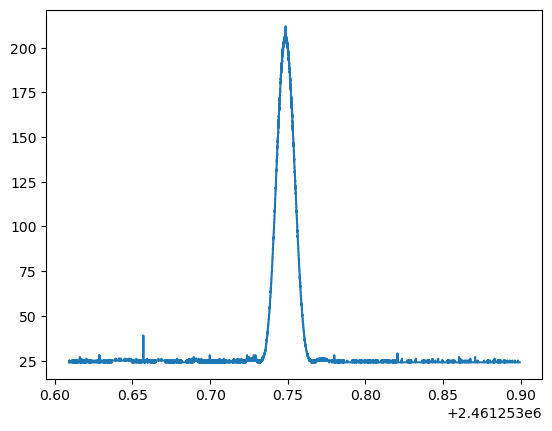

In [57]:
plt.plot(x,y)

# Compute date and time of the peak

In [58]:
from zoneinfo import ZoneInfo
from astropy.time import Time

# Find Julian Date of the peak

jd_value = x[np.argmax(y)]

# Parse the Julian Date into an Astropy Time object (in UTC)
t_utc = Time(jd_value, format="jd", scale="utc")

# Convert to a Python datetime object with Hong Kong Time zone
t_hk = t_utc.to_datetime(timezone=ZoneInfo("Asia/Hong_Kong"))

print("UTC Time:      ", t_utc.iso)
print("Hong Kong Time:", t_hk.strftime("%Y-%m-%d %H:%M:%S %Z"))

UTC Time:       2026-08-01 05:57:57.166
Hong Kong Time: 2026-08-01 13:57:57 HKT


In [59]:
beam = get_beam_angle(x,y)
print('Main beam angle: %.2f deg'%beam)

Main beam angle: 4.51 deg


###### TIME INFO #######
UTC Time:       2026-08-01 05:57:57.330
Hong Kong Time: 2026-08-01 13:57:57 HKT
### Gaussian Fit ###
Amplitude 183.97269780545105
Centre [Julian date] 2461253.7485802057
Sigma [Days] 0.0055167761052510415
Sigma [min] 7.9441575915615
Background floor [adu] 24.186843208255922
FWHM [days] 0.012991014708167258
FWHM [min] 18.707061179760853
Estimated antenna beam with 0.25 deg/min 4.676765294940213


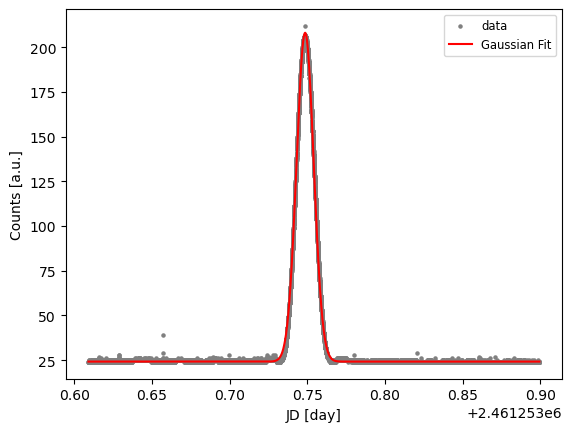

In [60]:
Amp_adu, centre_jd, sigma_jd, floor_adu, fwhm_day =  gauss_fit(x,y,verbose=True,plot=True)

In [61]:
# jd of centre of gaussian
t_utc = Time(centre_jd, format="jd", scale="utc")

# Convert to a Python datetime object with Hong Kong Time zone
t_hk = t_utc.to_datetime(timezone=ZoneInfo("Asia/Hong_Kong"))

print("UTC Time:      ", t_utc.iso)
print("Hong Kong Time:", t_hk.strftime("%Y-%m-%d %H:%M:%S %Z"))

UTC Time:       2026-08-01 05:57:57.330
Hong Kong Time: 2026-08-01 13:57:57 HKT


In [62]:
def get_conversion_K(julian_dates, counts_adu, amp_adu, solar_flux_sfu, aperture_eff=0.60):
    k_B = 1.38e-23  # Boltzmann constant [J/K]
    dish_diameter = 3.0  # Dish diameter in meters


    # Calculate Effective Aperture
    A_geom = np.pi * (dish_diameter / 2) ** 2
    A_e = aperture_eff * A_geom

    # Convert SFU to W/m^2/Hz
    S_flux = solar_flux_sfu * 1e-22

    # Expected Antenna Temperature of the Sun
    T_sun_expected = (S_flux * A_e) / (2 * k_B)

    # Calculate Calibration Factor K
    K = T_sun_expected / amp_adu

    return K

## Get Solar flux from https://sws.bom.gov.au/World_Data_Centre/1/10
### (Remember to set the date)

In [63]:
import pandas as pd
import requests

# 1. Define date (Learmonth files use YYMMDD format, e.g., '240724' for July 24, 2024)
# Note: Learmonth archives daily files formatted as L<YYMMDD>.SRD

date_str = "260806"  # YYMMDD


url = f"https://sws.bom.gov.au/Category/World%20Data%20Centre/Data%20Display%20and%20Download/Solar%20Radio/station/learmonth/SRD/2026/L{date_str}.SRD"

# 2. Fetch file directly from Australian BOM FTP/HTTP mirror
response = requests.get(url)

if response.status_code == 200:
    # Column names corresponding to the 8 frequencies in Learmonth SRD format
    col_names = [
        "time_ut",
        "f_245MHz",
        "f_410MHz",
        "f_610MHz",
        "flux_1_4GHz",  # 1415 MHz channel
        "f_2695MHz",
        "f_4975MHz",
        "f_8800MHz",
        "f_15400MHz",
    ]

    # Read space-separated values, treating '//////' or non-numeric entries as NaN
    df = pd.read_csv(
        io.StringIO(response.text),
        sep=r"\s+",
        names=col_names,
        na_values=["//////", "------"],
        on_bad_lines="skip",
    )

    # Convert HHMMSS string column into proper timestamp format
    date_prefix = f"20{date_str[:2]}-{date_str[2:4]}-{date_str[4:6]}"
    df["time_ut_clean"] = df["time_ut"].astype(str).str.zfill(6)
    df["datetime"] = pd.to_datetime(
        date_prefix + " " + df["time_ut_clean"],
        format="%Y-%m-%d %H%M%S",
        errors="coerce",
    )

    # Filter out any rows with invalid timestamps or missing 1.4GHz flux
    df_clean = df.dropna(subset=["datetime", "flux_1_4GHz"]).copy()

    print(
        f"Successfully loaded {len(df_clean)} records for 1.4 GHz (1415 MHz)!"
    )
    print(df_clean[["datetime", "time_ut", "flux_1_4GHz"]].head())
    print("\n")
    
    # 1. Daytime Average (Filters out nighttime zero/near-zero values)
    daytime_data = df_clean[df_clean["flux_1_4GHz"] > 10]
    daytime_avg = daytime_data["flux_1_4GHz"].mean()

    # 2. Raw 24-Hour Average (All records)
    raw_avg = df_clean["flux_1_4GHz"].mean()

    print(f"Daytime Solar Average (1.4 GHz): {daytime_avg:.2f} SFU")
    print(f"Raw 24-Hour Average (1.4 GHz):   {raw_avg:.2f} SFU")
    print("\n")
    
    
    f14 = daytime_avg
    
    K = get_conversion_K(x,y,amp_adu=Amp_adu,solar_flux_sfu=f14)

    print('Conversion factor between ADU to Antenna temperature: ',K)

Successfully loaded 39392 records for 1.4 GHz (1415 MHz)!
             datetime  time_ut  flux_1_4GHz
3 2026-08-06 00:00:03        3         67.0
4 2026-08-06 00:00:04        4         67.0
5 2026-08-06 00:00:05        5         69.0
6 2026-08-06 00:00:06        6         69.0
7 2026-08-06 00:00:07        7         68.0


Daytime Solar Average (1.4 GHz): 65.46 SFU
Raw 24-Hour Average (1.4 GHz):   62.26 SFU


Conversion factor between ADU to Antenna temperature:  5.46793637591984


# Plot antenna Temperature

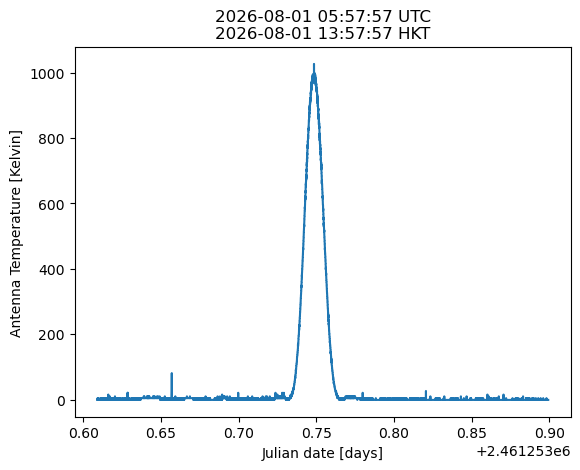

In [64]:
AntennaTemp = (y-floor_adu)*K

plt.plot(x, AntennaTemp)
plt.xlabel('Julian date [days]')
plt.ylabel('Antenna Temperature [Kelvin]')
plt.title(t_utc.iso[:-4]+" UTC\n"+t_hk.strftime("%Y-%m-%d %H:%M:%S %Z"))
plt.show()

# Convert to temperature Brightness

In [65]:
def ta_to_tb(T_A, beamwidth_deg=4.6, source_deg=0.553, eta_mb=0.7):
    """
    Converts Antenna Temperature to Brightness Temperature using a measured beamwidth.
    """
    # Convert measured beamwidth to radians
    theta_beam_rad = np.radians(beamwidth_deg)

    # Gaussian beam solid angle of the telescope
    omega_A = 1.133 * (theta_beam_rad ** 2)

    # Source solid angle (~0.533 degrees diameter for the Sun)
    theta_source_rad = np.radians(0.533)
    omega_source = np.pi * (theta_source_rad / 2) ** 2

    # Dilution ratio
    dilution_ratio = omega_A / omega_source

    # Intrinsic Brightness Temperature
    T_B = (T_A / eta_mb) * dilution_ratio

    return T_B

In [66]:
BrightnessTemp = ta_to_tb(AntennaTemp,beamwidth_deg=beam)

# Plot Temperature Brightness

Temperature Brightness (peak) =  151352.00741553132


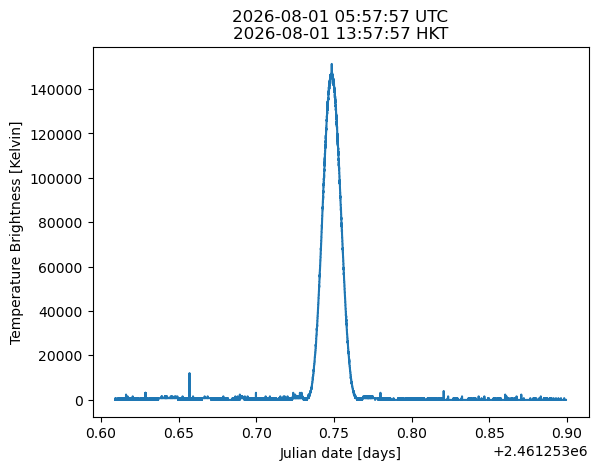

In [67]:
plt.plot(x, BrightnessTemp)
plt.xlabel('Julian date [days]')
plt.ylabel('Temperature Brightness [Kelvin]')
plt.title(t_utc.iso[:-4]+" UTC\n"+t_hk.strftime("%Y-%m-%d %H:%M:%S %Z"))
print('Temperature Brightness (peak) = ',BrightnessTemp.max() )
plt.show()